In [3]:
# pip install diffusers

In [1]:
from diffusers import AutoencoderKL
import glob
import matplotlib.pyplot as plt
import os
from PIL import Image
import torch
import torchvision.transforms as transforms

In [3]:
# 1. Device Configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [4]:
# 2. Load Pre-trained Stable Diffusion VAE (Zero training required!)
print("Loading pre-trained stabilityai/sd-vae-ft-mse...")
vae = AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-mse").to(device)
vae.eval()

Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.


Loading pre-trained stabilityai/sd-vae-ft-mse...


AutoencoderKL(
  (encoder): Encoder(
    (conv_in): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (down_blocks): ModuleList(
      (0): DownEncoderBlock2D(
        (resnets): ModuleList(
          (0-1): 2 x ResnetBlock2D(
            (norm1): GroupNorm(32, 128, eps=1e-06, affine=True)
            (conv1): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (norm2): GroupNorm(32, 128, eps=1e-06, affine=True)
            (dropout): Dropout(p=0.0, inplace=False)
            (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (nonlinearity): SiLU()
          )
        )
        (downsamplers): ModuleList(
          (0): Downsample2D(
            (conv): Conv2d(128, 128, kernel_size=(3, 3), stride=(2, 2))
          )
        )
      )
      (1): DownEncoderBlock2D(
        (resnets): ModuleList(
          (0): ResnetBlock2D(
            (norm1): GroupNorm(32, 128, eps=1e-06, affine=True)
            (c

In [5]:
# 3. Specify your local image directory path
image_dir = r"D:\AIML_LEARN\Academics\DCS Semantic Communications\deep_jscc\image_2"

# Automatically find all PNG and JPG images in your folder
image_paths = sorted(glob.glob(os.path.join(image_dir, "*.png"))) + sorted(
    glob.glob(os.path.join(image_dir, "*.jpg"))
)

if not image_paths:
  print(f"No images found in path: {image_dir}")
else:
  print(f"Found {len(image_paths)} custom images in folder!")

Found 200 custom images in folder!


In [6]:
# 4. Define Image Transforms (Resize to 512x512 and normalize to [-1, 1] for SD VAE)
transform = transforms.Compose(
    [
        transforms.Resize((512, 512)),
        transforms.ToTensor(),
        transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
    ]
)

In [7]:
# 5. 6G JSCC Human Mode Pipeline with AWGN Channel Simulation
def run_human_mode_pipeline(image_tensor, snr_db=None):
  with torch.no_grad():
    # --- TRANSMITTER: ENCODER ---
    # Compresses high-res image into a latent bottleneck tensor
    latent_dist = vae.encode(image_tensor).latent_dist
    latent = latent_dist.sample()

    # --- 6G CHANNEL: ADDITIVE WHITE GAUSSIAN NOISE (AWGN) ---
    if snr_db is not None:
      signal_power = torch.mean(latent**2)
      snr_linear = 10 ** (snr_db / 10.0)
      noise_variance = signal_power / snr_linear
      noise = torch.randn_like(latent) * torch.sqrt(noise_variance)
      latent = latent + noise  # Corrupt latent embedding with channel noise

    # --- RECEIVER: DECODER (Human Mode) ---
    # Reconstructs high-fidelity image from the noisy latent representation
    reconstructed = vae.decode(latent).sample
    return reconstructed

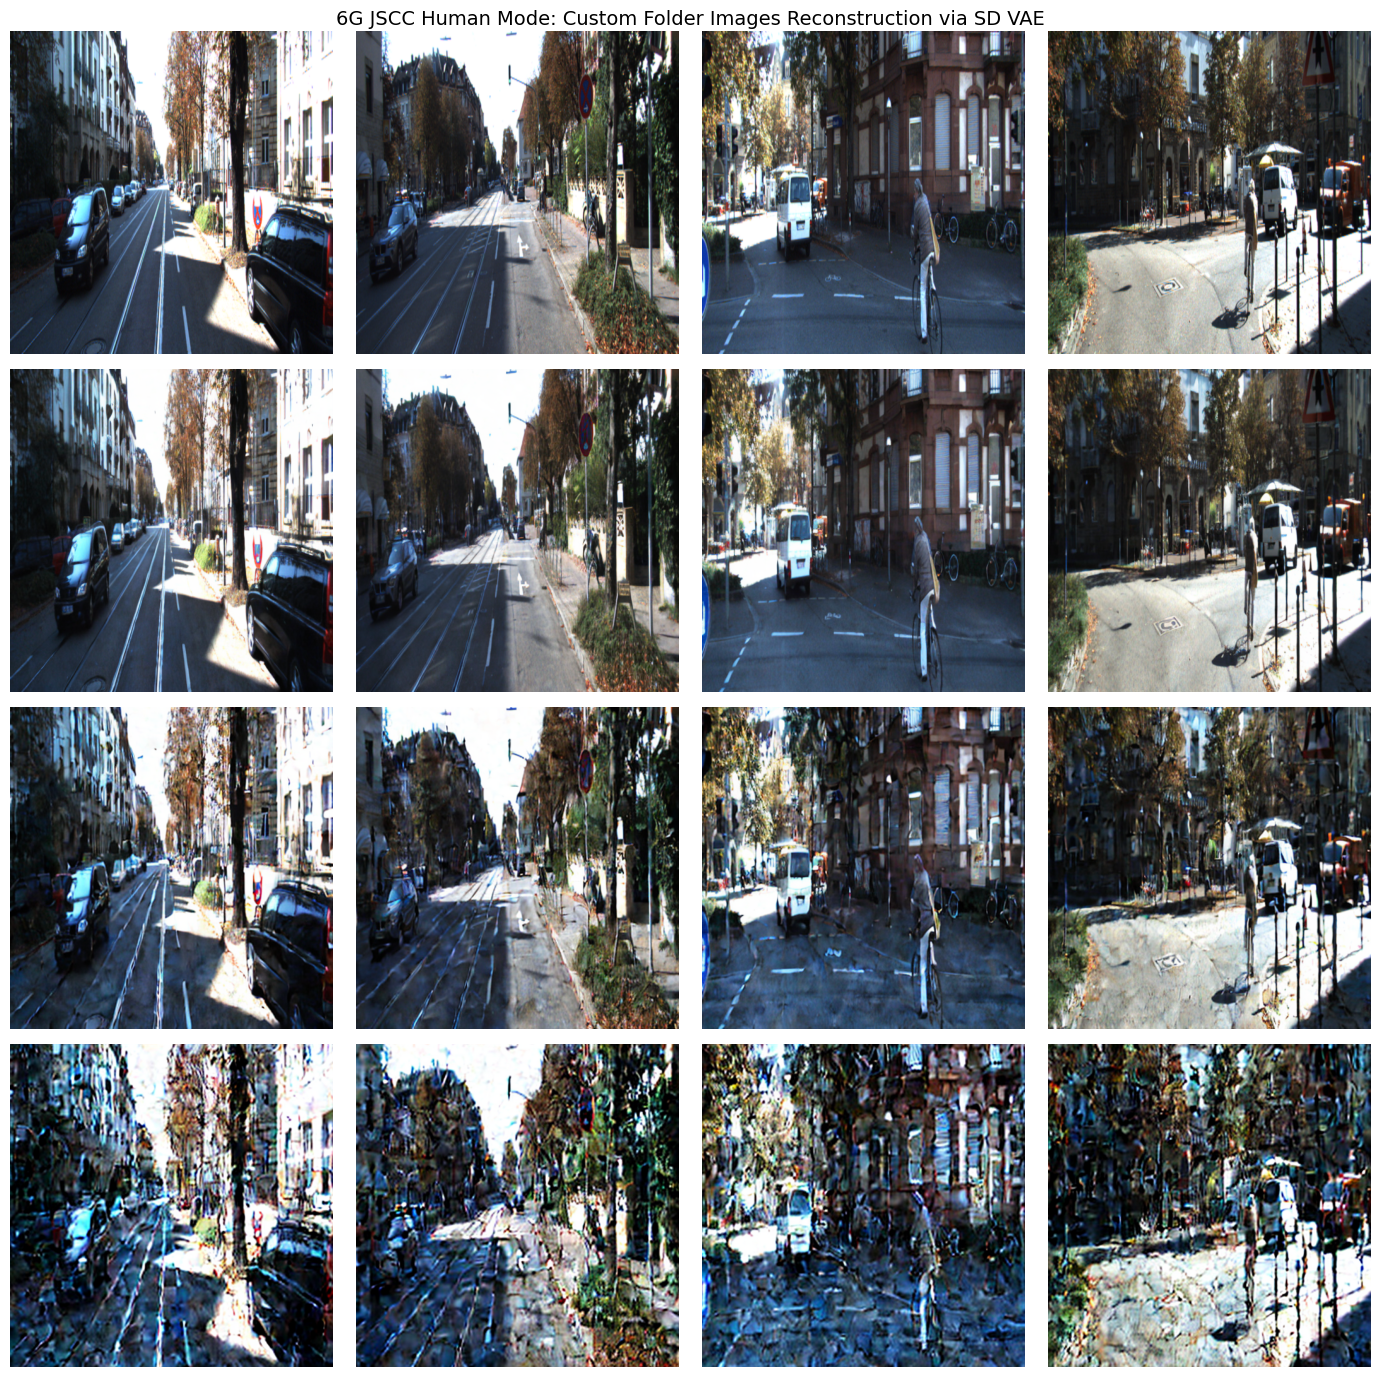

In [8]:
# 6. Load up to 4 custom images from your folder and run the pipeline
if image_paths:
  batch_images = []
  # Load first few images (or change slice [0:4] to pick specific ones)
  for path in image_paths[:4]:
    img = Image.open(path).convert("RGB")
    batch_images.append(transform(img))

  images_tensor = torch.stack(batch_images).to(device)

  # Define channel SNR test levels (None = clean channel, others = noisy in dB)
  snr_levels = [None, 20, 10, 5]
  fig, axes = plt.subplots(
      len(snr_levels), len(images_tensor), figsize=(14, 3.5 * len(snr_levels))
  )

  for row, snr in enumerate(snr_levels):
    recons = run_human_mode_pipeline(images_tensor, snr_db=snr)

    # Post-process tensors for plotting (convert from [-1, 1] back to [0, 1])
    recons = (recons / 2.0 + 0.5).clamp(0, 1)
    originals = (images_tensor / 2.0 + 0.5).clamp(0, 1)

    for col in range(len(images_tensor)):
      ax = axes[row, col] if len(snr_levels) > 1 else axes[col]
      img_tensor = originals[col] if row == 0 else recons[col]

      ax.imshow(img_tensor.cpu().permute(1, 2, 0).numpy())
      ax.axis("off")

      if col == 0:
        label = "Original Custom" if row == 0 else f"SNR: {snr} dB"
        ax.set_ylabel(label, fontsize=11, weight="bold")

  plt.suptitle(
      "6G JSCC Human Mode: Custom Folder Images Reconstruction via SD VAE",
      fontsize=14,
      y=0.98,
  )
  plt.tight_layout()
  plt.show()

Found 200 custom images in folder!


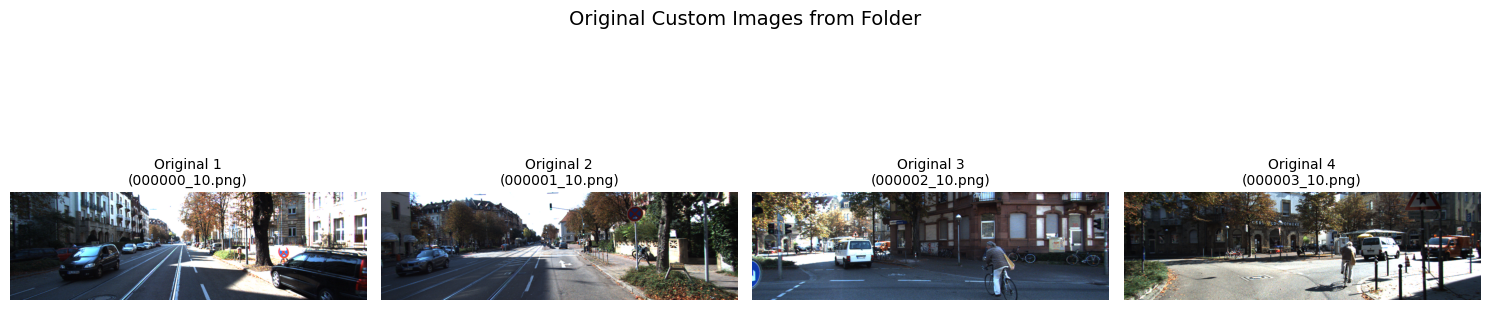

In [9]:
from PIL import Image

# 1. Specify your local image directory path
image_dir = r"D:\AIML_LEARN\Academics\DCS Semantic Communications\deep_jscc\image_2"

# Automatically find all PNG and JPG images in your folder
image_paths = sorted(glob.glob(os.path.join(image_dir, "*.png"))) + sorted(
    glob.glob(os.path.join(image_dir, "*.jpg"))
)

if not image_paths:
  print(f"No images found in path: {image_dir}")
else:
  print(f"Found {len(image_paths)} custom images in folder!")

  # 2. Choose how many images to display (e.g., first 4)
  num_images_to_show = min(4, len(image_paths))

  fig, axes = plt.subplots(1, num_images_to_show, figsize=(15, 4))

  # Handle case if only 1 image is found
  if num_images_to_show == 1:
    axes = [axes]

  for i in range(num_images_to_show):
    img_path = image_paths[i]
    img = Image.open(img_path).convert("RGB")

    # Plot original image
    axes[i].imshow(img)
    axes[i].axis("off")
    axes[i].set_title(
        f"Original {i+1}\n({os.path.basename(img_path)})", fontsize=10
    )

  plt.suptitle("Original Custom Images from Folder", fontsize=14, y=1.05)
  plt.tight_layout()
  plt.show()